# Tech Challenge Fase 1, diagnóstico de diabetes com machine learning

Aqui eu monto um modelo que ajuda na triagem de diabetes a partir de dados clínicos simples. A ideia é apoiar o médico, apontando quem merece um olhar mais cuidadoso. A decisão final continua sendo dele.

Usei a base Pima Indians Diabetes, a mesma indicada no enunciado. São 768 pacientes, todas mulheres com 21 anos ou mais da população Pima, com 8 variáveis e a coluna Outcome dizendo se a paciente tem diabetes (1) ou não (0).

Organizei o trabalho seguindo as etapas do CRISP-DM que vimos em Fundamentos de IA. Entender o problema, entender os dados, preparar, modelar, avaliar e discutir se dá para usar na prática.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import pandas as pd

from diabetes import avaliacao, exploracao
from diabetes.config import NOMES_PT
from diabetes.dados import carregar_dados, contar_zeros_invalidos, marcar_zeros_como_faltantes, separar_treino_teste
from diabetes.modelagem import (
    GRADE_RANDOM_FOREST,
    GRADE_REGRESSAO_LOGISTICA,
    ajustar_hiperparametros,
    comparar_na_validacao_cruzada,
    pipeline_base,
    pipeline_random_forest,
    pipeline_regressao_logistica,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Conhecendo a base

In [2]:
dados_brutos = carregar_dados()
print(dados_brutos.shape)
dados_brutos.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
dados_brutos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
dados_brutos.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Logo no describe já aparece o primeiro problema. Glicose, pressão, dobra cutânea, insulina e IMC têm mínimo igual a zero, e isso não existe numa pessoa viva. Esses zeros são dado faltando disfarçado.

In [5]:
print("Linhas duplicadas", dados_brutos.duplicated().sum())
print("Valores nulos", dados_brutos.isna().sum().sum())

Linhas duplicadas 0
Valores nulos 0


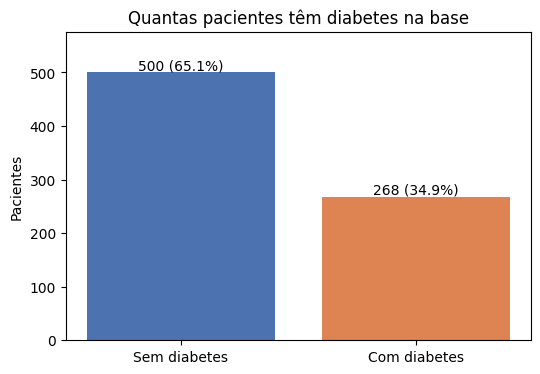

In [6]:
exploracao.grafico_distribuicao_alvo(dados_brutos)
plt.show()

A base não é equilibrada. Cerca de 65% das pacientes não têm diabetes e 35% têm. Isso pesa em duas decisões. Vou separar treino e teste mantendo essa proporção (stratify) e não vou confiar só na acurácia, porque um modelo que chuta sempre "sem diabetes" já acerta uns 65%.

## 2. Zeros que na verdade são dado faltando

In [7]:
tabela_zeros = contar_zeros_invalidos(dados_brutos)
tabela_zeros

,zeros,percentual
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


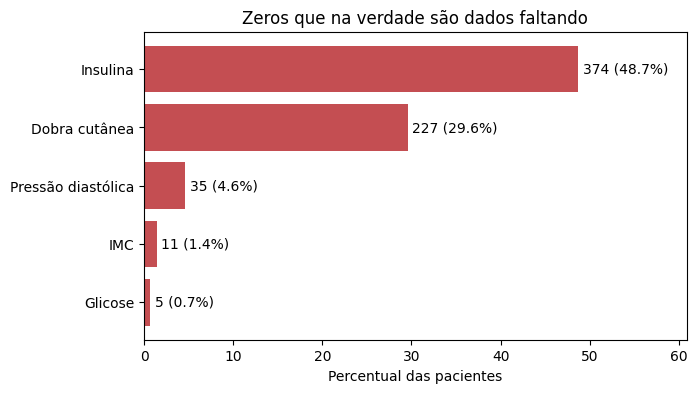

In [8]:
exploracao.grafico_zeros_invalidos(tabela_zeros)
plt.show()

Quase metade das pacientes está sem insulina e quase 30% sem a dobra cutânea. Apagar essas linhas jogaria fora metade da base, então troco os zeros por vazio (NaN) e depois preencho com a mediana. A mediana é calculada só com os dados de treino, dentro do Pipeline, para não vazar informação do teste.

Gestações igual a zero é normal, por isso essa coluna fica de fora da troca.

In [9]:
dados = marcar_zeros_como_faltantes(dados_brutos)
dados.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [10]:
dados.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
BloodPressure,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
SkinThickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
Insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
BMI,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 3. Análise exploratória

In [11]:
dados.groupby("Outcome").median().T.rename(index=NOMES_PT).round(1)

Outcome,0,1
Gestações,2.0,4.0
Glicose,107.0,140.0
Pressão diastólica,70.0,74.5
Dobra cutânea,27.0,32.0
Insulina,102.5,169.5
IMC,30.1,34.3
Histórico familiar,0.3,0.4
Idade,27.0,36.0


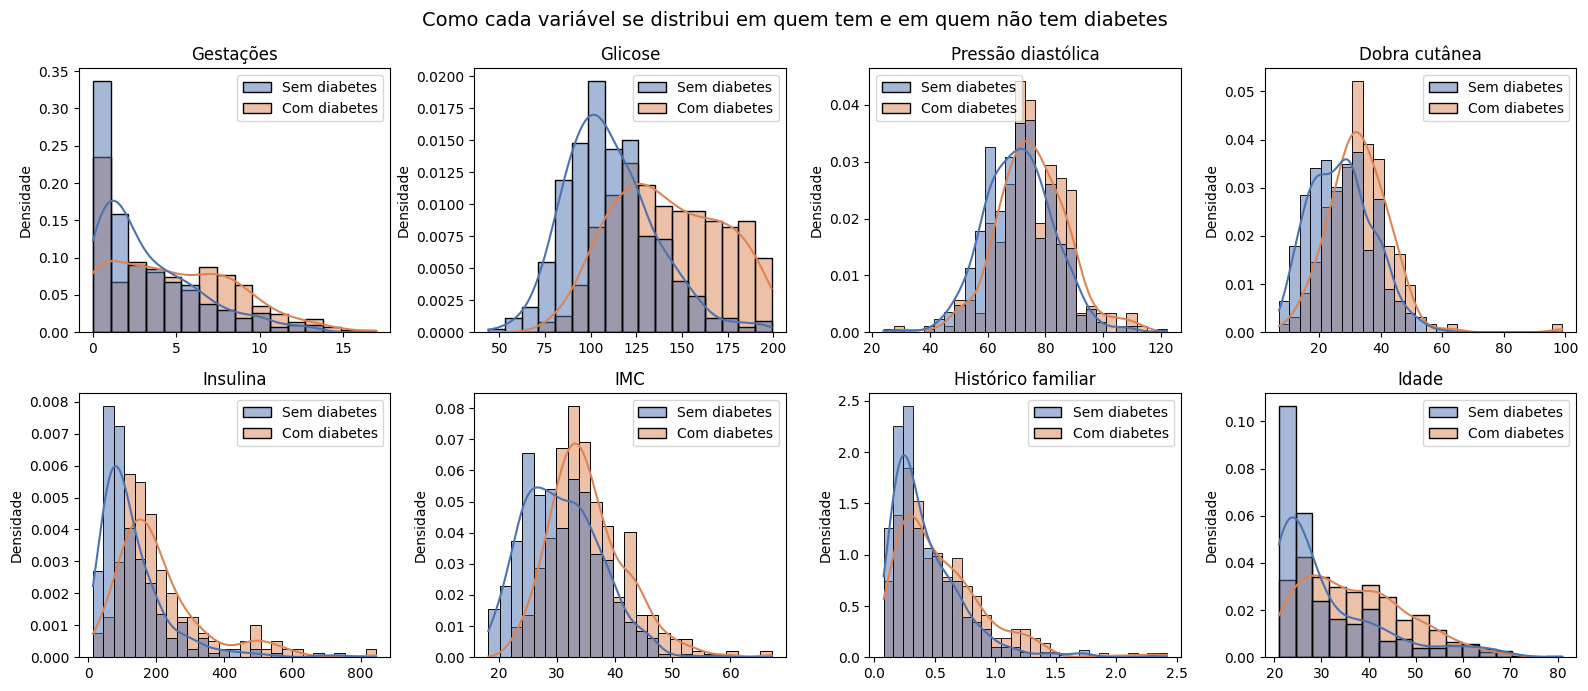

In [12]:
exploracao.grafico_histogramas_por_classe(dados)
plt.show()

A glicose é a variável que mais separa os grupos. Quem tem diabetes concentra valores bem mais altos. IMC, idade e gestações também deslocam a curva para a direita, mas com muito mais mistura entre os dois grupos.

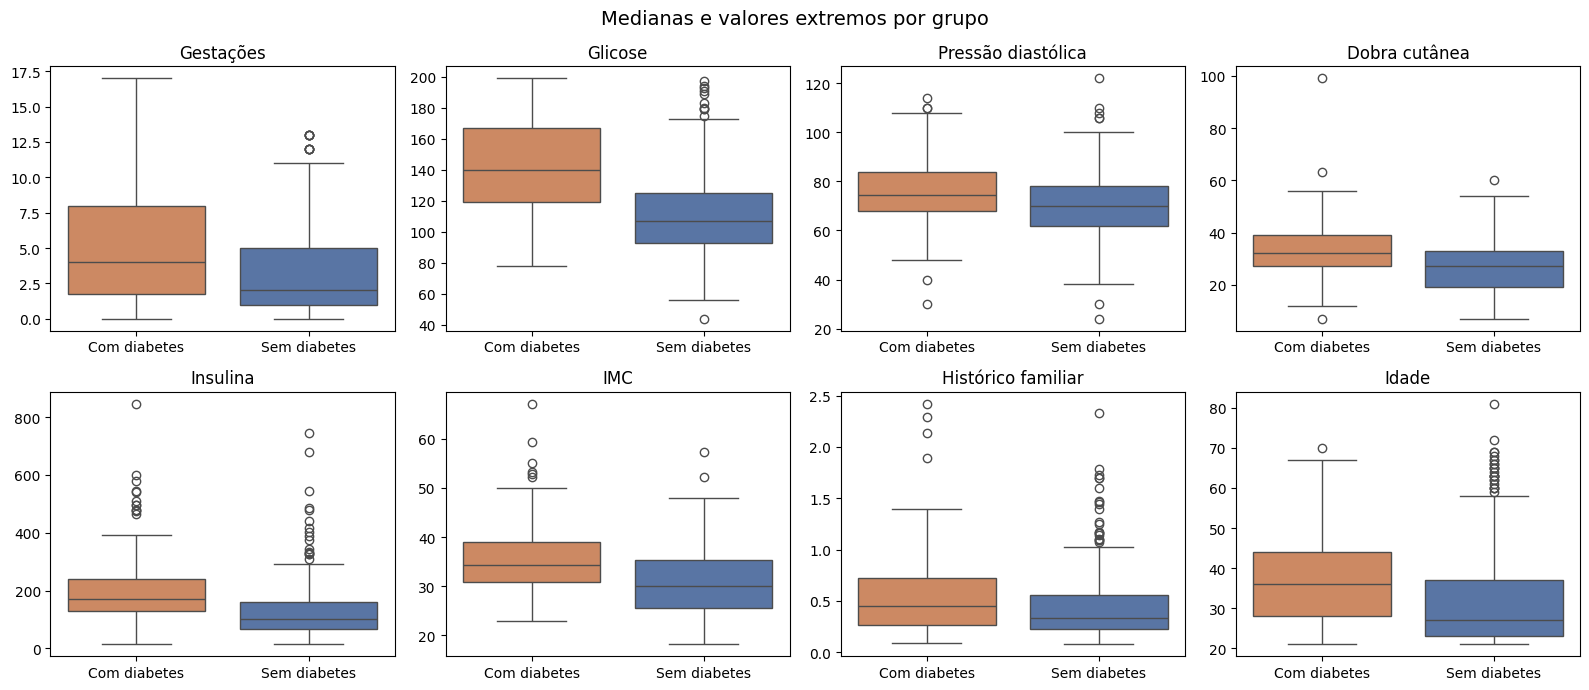

In [13]:
exploracao.grafico_boxplots_por_classe(dados)
plt.show()

Os boxplots confirmam as medianas mais altas no grupo com diabetes e mostram valores extremos principalmente em insulina e dobra cutânea. Não removi esses pontos porque são valores possíveis clinicamente e a base é pequena.

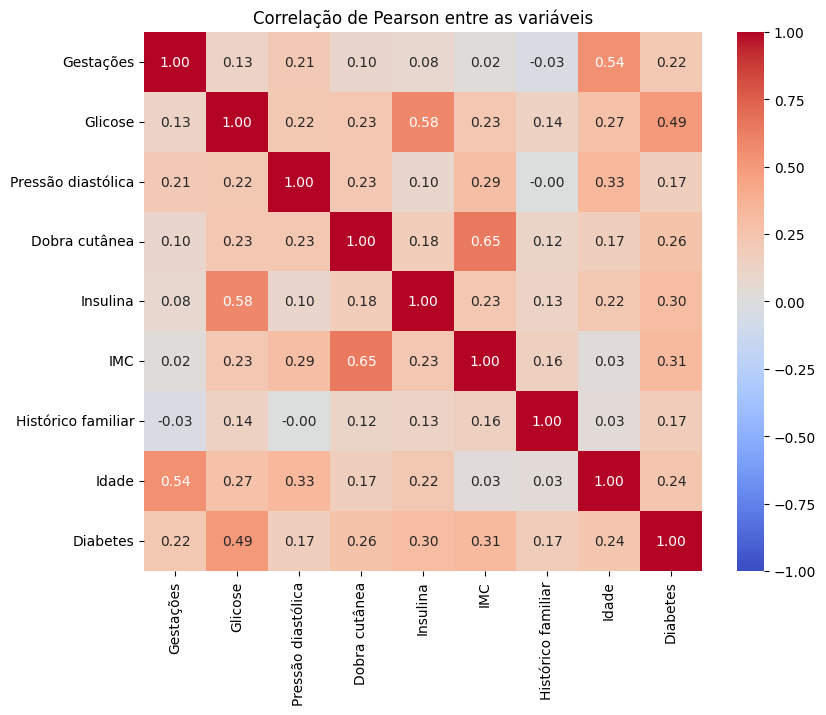

In [14]:
exploracao.grafico_correlacao(dados)
plt.show()

In [15]:
dados.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).rename(NOMES_PT).round(3)

Glicose               0.495
IMC                   0.314
Insulina              0.303
Dobra cutânea         0.259
Idade                 0.238
Gestações             0.222
Histórico familiar    0.174
Pressão diastólica    0.171
Name: Outcome, dtype: float64

Pela correlação de Pearson, a glicose tem a relação mais forte com o diagnóstico (0,49), seguida de IMC e insulina. Entre as variáveis, idade e gestações andam juntas (0,54), o que faz sentido, e IMC com dobra cutânea também (0,65).

Correlação não é causa. Ela mostra quais variáveis andam juntas, não prova que uma provoca a outra.

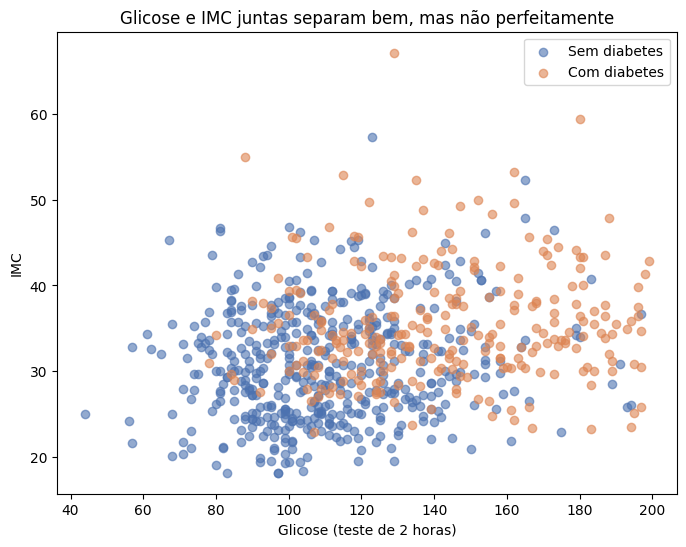

In [16]:
exploracao.grafico_glicose_imc(dados)
plt.show()

Glicose e IMC juntas já separam bem os grupos, mas sobra uma região grande de mistura no meio. É ali que o modelo vai errar, e é por isso que ele não substitui o exame e o médico.

## 4. Separação de treino e teste

Separo 20% das pacientes para o teste final, mantendo a proporção de diabetes nos dois lados. O teste fica guardado e só é usado uma vez, no fim. Toda escolha de modelo e de parâmetro é feita com validação cruzada dentro do treino.

In [17]:
x_treino, x_teste, y_treino, y_teste = separar_treino_teste(dados)
print("Treino", x_treino.shape, "Teste", x_teste.shape)
print("Proporção de diabetes no treino", round(y_treino.mean(), 3))
print("Proporção de diabetes no teste", round(y_teste.mean(), 3))

Treino (614, 8) Teste (154, 8)
Proporção de diabetes no treino 0.349
Proporção de diabetes no teste 0.351


## 5. Modelos

Escolhi dois modelos com perfis diferentes.

- **Regressão Logística.** Simples, rápida e fácil de explicar, porque cada variável recebe um peso. Ela precisa das variáveis na mesma escala, então o Pipeline tem imputação pela mediana, StandardScaler e o modelo.
- **Random Forest.** Um conjunto de árvores de decisão que votam juntas. Pega relações não lineares, não precisa de escala e combina muito bem com o SHAP para explicar as previsões.

Também uso um **modelo base (DummyClassifier)** que chuta sempre a classe mais comum. Ele serve de piso. Se um modelo não passa dele, não serve para nada.

Os hiperparâmetros foram escolhidos com GridSearchCV e validação cruzada estratificada de 5 dobras, otimizando o F1, que equilibra precisão e recall.

In [18]:
busca_rl = ajustar_hiperparametros(pipeline_regressao_logistica(), GRADE_REGRESSAO_LOGISTICA, x_treino, y_treino)
busca_rf = ajustar_hiperparametros(pipeline_random_forest(), GRADE_RANDOM_FOREST, x_treino, y_treino)
print("Regressão Logística", busca_rl.best_params_)
print("Random Forest", busca_rf.best_params_)

Regressão Logística {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'}
Random Forest {'modelo__class_weight': 'balanced', 'modelo__max_depth': 4, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 400}


Nos dois modelos o class_weight balanced venceu. Ele dá mais peso às pacientes com diabetes durante o treino, compensando o desequilíbrio da base. Na Random Forest venceram árvores rasas (profundidade 4) e folhas com pelo menos 10 pacientes, o que evita decorar a base.

## 6. Comparação na validação cruzada

Comparo os modelos pela média e pelo desvio das 5 dobras. O desvio mostra se o resultado é estável ou se foi sorte de uma divisão.

In [19]:
modelos = {
    "Regressão Logística": busca_rl.best_estimator_,
    "Random Forest": busca_rf.best_estimator_,
}
comparacao = comparar_na_validacao_cruzada({"Modelo base (Dummy)": pipeline_base(), **modelos}, x_treino, y_treino)
comparacao

,acuracia_media,acuracia_desvio,precisao_media,precisao_desvio,recall_media,recall_desvio,f1_media,f1_desvio,roc_auc_media,roc_auc_desvio
modelo,,,,,,,,,,
Modelo base (Dummy),0.651,0.002,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
Regressão Logística,0.767,0.008,0.651,0.020,0.720,0.050,0.682,0.017,0.845,0.013
Random Forest,0.780,0.015,0.662,0.029,0.762,0.017,0.707,0.010,0.840,0.020


Os dois modelos passam bem do modelo base. A Random Forest fica um pouco à frente em recall e F1, enquanto a ROC AUC dos dois é praticamente igual, com diferença menor que o desvio entre as dobras. Ou seja, os dois ordenam as pacientes por risco quase do mesmo jeito.

## 7. Qual métrica importa mais

Num problema de triagem, o pior erro é dizer que a paciente não tem diabetes quando ela tem (falso negativo). Ela vai embora sem acompanhamento. Por isso o **recall da classe com diabetes** é a métrica principal. O F1 entra para não deixar a precisão despencar, porque falso positivo demais sobrecarrega o médico com exames desnecessários. A acurácia fica só como referência.

## 8. Ajuste do limiar de decisão

Por padrão o modelo diz "com diabetes" quando a probabilidade passa de 0,5. Como o recall é a prioridade, testei baixar esse limiar. A escolha foi feita com as probabilidades da validação cruzada do treino, nunca com o teste. A regra foi pegar o limiar com a maior precisão possível garantindo recall de pelo menos 80%.

Limiar escolhido 0.46


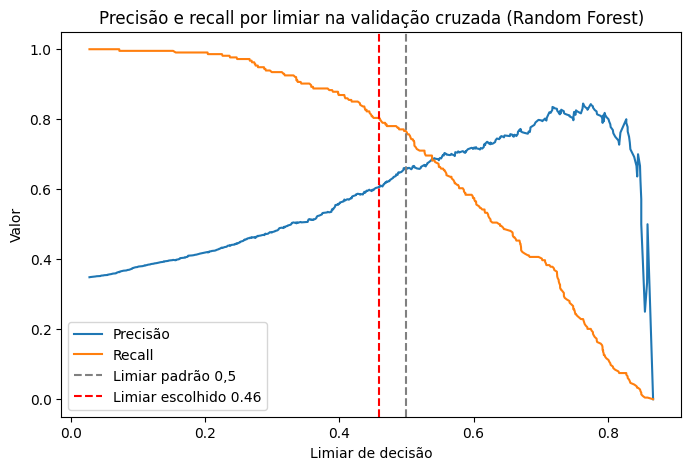

In [20]:
limiar_rf, probabilidades_oof = avaliacao.escolher_limiar(busca_rf.best_estimator_, x_treino, y_treino)
print("Limiar escolhido", round(limiar_rf, 3))
avaliacao.grafico_precisao_recall_por_limiar(y_treino, probabilidades_oof, limiar_rf, "Random Forest")
plt.show()

## 9. Avaliação final no teste

Agora sim uso o teste, uma única vez.

In [21]:
avaliacao.metricas_no_teste(modelos, x_teste, y_teste)

,limiar,acuracia,precisao,recall,f1,roc_auc
modelo,,,,,,
Regressão Logística,0.5,0.708,0.571,0.667,0.615,0.810
Random Forest,0.5,0.734,0.597,0.741,0.661,0.814


In [22]:
avaliacao.metricas_no_teste(
    {"Random Forest com limiar ajustado": busca_rf.best_estimator_},
    x_teste,
    y_teste,
    {"Random Forest com limiar ajustado": limiar_rf},
)

,limiar,acuracia,precisao,recall,f1,roc_auc
modelo,,,,,,
Random Forest com limiar ajustado,0.46,0.721,0.573,0.796,0.667,0.814


In [23]:
for nome, modelo in modelos.items():
    print(nome)
    print(avaliacao.relatorio_classificacao(modelo, x_teste, y_teste))
print("Random Forest com limiar ajustado")
print(avaliacao.relatorio_classificacao(busca_rf.best_estimator_, x_teste, y_teste, limiar_rf))

Regressão Logística
              precision    recall  f1-score   support

Sem diabetes      0.802     0.730     0.764       100
Com diabetes      0.571     0.667     0.615        54

    accuracy                          0.708       154
   macro avg      0.687     0.698     0.690       154
weighted avg      0.721     0.708     0.712       154

Random Forest
              precision    recall  f1-score   support

Sem diabetes      0.839     0.730     0.781       100
Com diabetes      0.597     0.741     0.661        54

    accuracy                          0.734       154
   macro avg      0.718     0.735     0.721       154
weighted avg      0.754     0.734     0.739       154

Random Forest com limiar ajustado
              precision    recall  f1-score   support

Sem diabetes      0.861     0.680     0.760       100
Com diabetes      0.573     0.796     0.667        54

    accuracy                          0.721       154
   macro avg      0.717     0.738     0.713       154
weight

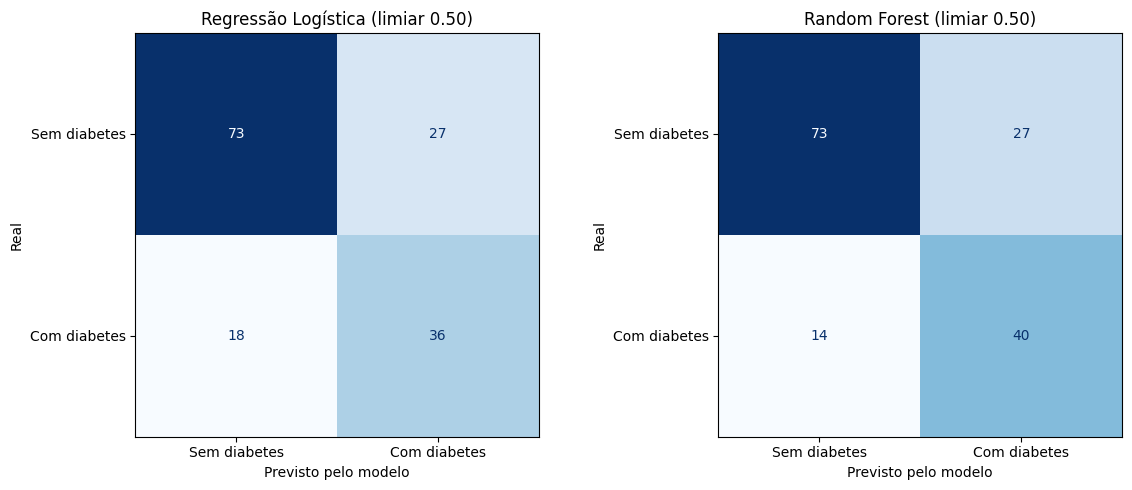

In [24]:
avaliacao.grafico_matrizes_confusao(modelos, x_teste, y_teste)
plt.show()

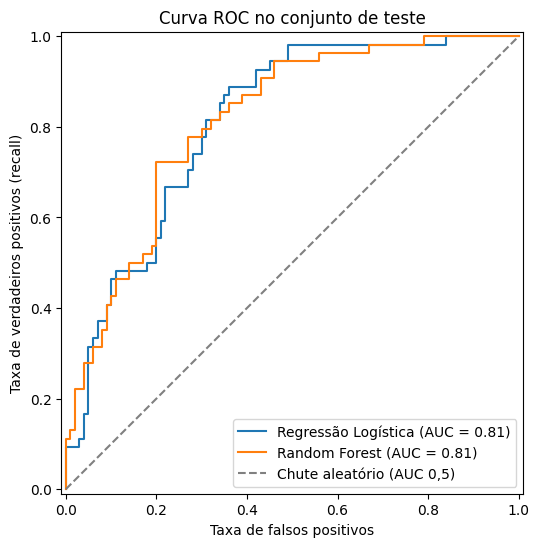

In [25]:
avaliacao.grafico_curva_roc(modelos, x_teste, y_teste)
plt.show()

No teste a Random Forest acertou 40 das 54 pacientes com diabetes e a Regressão Logística 36. Com o limiar ajustado a Random Forest sobe para 43 de 54 (recall perto de 80%), em troca de mais alguns falsos positivos. As duas curvas ROC ficam bem acima da diagonal do chute aleatório e muito próximas entre si.

Os números do teste ficaram um pouco abaixo da validação cruzada. É esperado com só 154 pacientes, onde cada paciente vale quase 2 pontos de recall. Por isso olhei primeiro a média e o desvio da validação cruzada e só confirmei no teste.

## 10. O que o modelo olhou para decidir

In [26]:
coeficientes = avaliacao.coeficientes_regressao_logistica(busca_rl.best_estimator_)
coeficientes

,coeficiente,razao_de_chances
variavel,,
Glicose,1.024,2.784
IMC,0.599,1.820
Gestações,0.321,1.378
Histórico familiar,0.256,1.291
Idade,0.189,1.208
Dobra cutânea,0.059,1.061
Pressão diastólica,0.017,1.018
Insulina,0.016,1.016


In [27]:
importancias = avaliacao.importancias_random_forest(busca_rf.best_estimator_, x_teste, y_teste)
importancias

,importancia_impureza,importancia_permutacao,desvio_permutacao
variavel,,,
Glicose,0.373,0.091,0.023
IMC,0.188,0.045,0.018
Idade,0.132,0.031,0.010
Insulina,0.112,0.008,0.009
Histórico familiar,0.064,0.009,0.005
Dobra cutânea,0.047,0.001,0.004
Gestações,0.045,0.007,0.004
Pressão diastólica,0.038,-0.004,0.003


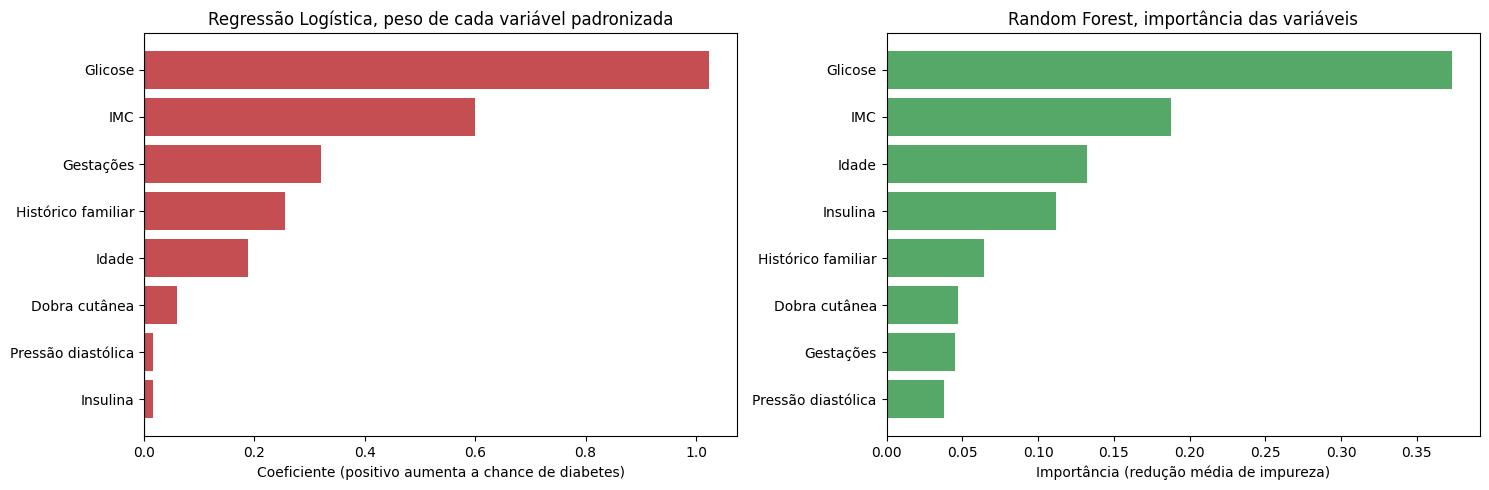

In [28]:
avaliacao.grafico_importancias(coeficientes, importancias)
plt.show()

Os dois modelos concordam no principal. Glicose é de longe a variável mais importante, seguida de IMC e idade. Na Regressão Logística, a razão de chances diz que cada desvio padrão a mais de glicose multiplica a chance de diabetes por quase 2,8.

Na Random Forest conferi também a importância por permutação no teste, que mede quanto a ROC AUC cai quando embaralho cada variável. Ela confirma a ordem glicose, IMC e idade.

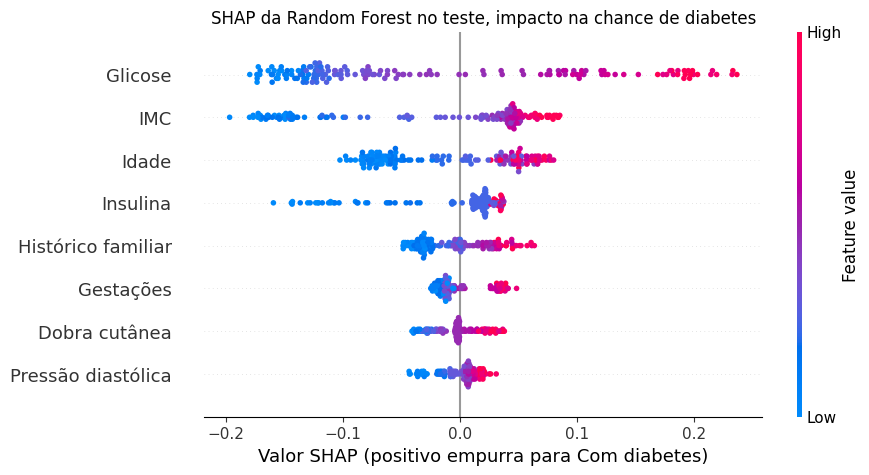

In [29]:
valores_shap = avaliacao.valores_shap_random_forest(busca_rf.best_estimator_, x_teste)
avaliacao.grafico_shap_resumo(valores_shap)
plt.show()

No SHAP cada ponto é uma paciente do teste. A cor mostra o valor da variável (vermelho alto, azul baixo) e a posição mostra se aquilo empurrou a previsão para "com diabetes" (direita) ou para "sem diabetes" (esquerda). Glicose alta, IMC alto e idade maior empurram para a direita, exatamente o que a literatura médica espera.

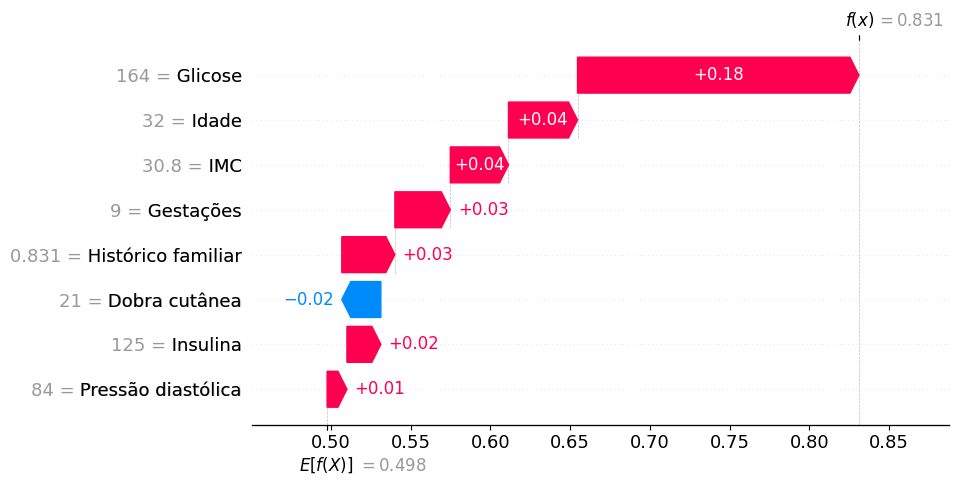

In [30]:
probabilidades_teste = busca_rf.best_estimator_.predict_proba(x_teste)[:, 1]
avaliacao.grafico_shap_paciente(valores_shap, int(probabilidades_teste.argmax()), "12_shap_paciente_maior_risco.png")
plt.show()

Esse é o exemplo de uma paciente só. O modelo partiu da média (cerca de 0,50) e chegou em 0,83 de probabilidade, puxado principalmente pela glicose de 164. É esse tipo de explicação que um médico consegue conferir e questionar.

## 11. Discussão crítica

O modelo é útil como apoio à triagem, para priorizar quem deve fazer exames confirmatórios. Ele não deve dar diagnóstico sozinho, e o médico tem a palavra final.

Limites que precisam ficar claros.

- A base tem só 768 pacientes, todas mulheres Pima com 21 anos ou mais. Não dá para garantir que funcione em homens, em outras etnias ou em quem já fez cirurgia bariátrica, que muda o metabolismo da glicose.
- A glicose da base é do teste oral de 2 horas, não a de jejum. Usar o modelo com glicose de jejum seria aplicar fora do que ele aprendeu.
- Metade dos valores de insulina era faltante. A mediana preenche o buraco, mas não traz a informação real.
- Mesmo com o limiar ajustado, o modelo ainda deixa passar cerca de 1 em cada 5 pacientes com diabetes no teste. Por isso ele não pode ser o único filtro.
- A amostra é antiga e de um grupo específico. Antes de qualquer uso real seria preciso validar com dados atuais da população onde o modelo vai rodar e acompanhar o desempenho ao longo do tempo.